# 2. Eccentricity Detectability for a Fiducial System

In [1]:
import numpy as np
import scipy as sp
import pandas as pd

import sys
sys.path.append("../emri_tools")
from utils import load_hdf5, PSD
from gw_signal import get_frequency_evolution

import matplotlib.pyplot as plt
from seaborn import color_palette
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": "Computer Modern",
    "text.latex.preamble": r"\usepackage{amsfonts}",
    "font.size": 17,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "legend.frameon": False
})

In [2]:
tdi_flag = False
psd = PSD(tdi_flag)

Using LISA PSD


### Configuration

In [3]:
# Fiducial system's parameters
m1, m2 = 1e6, 10.0
a, Tpl = 0.9, 0.9
xI, dist = 1.0, 1.0
theta_S, phi_S = np.pi/3, 0
theta_K, phi_K = np.pi/3, 0

# Short-time Fourier Transform (SFT) and observation parameters
T_SFT = 2 * 86400   # SFT duration [seconds], corresponding to 2 days (default is 5e4)
T_DATA = 1.0        # Total observation time [years]
DELTA_T = 5.0       # Time step [seconds]
SNR_REF = 30.0      # Reference SNR for injection
T_SNR = 1.0         # SNR reference duration [years]

In [4]:
filenames = ["../results/2_fid_lambda_ef_20_mode.h5", 
             "../results/2_fid_lambda_ef_dom_mode.h5",
             "../results/2_fid_lambda_ef_75_thr.h5",
             "../results/2_fid_lambda_ef_90_thr.h5",
             "../results/2_fid_lambda_ef_99_thr.h5"]

labels = ["(2,0) Mode", 
          "Dominant Mode", 
          r"75\% SNR Threshold",
          r"90\% SNR Threshold",
          r"99\% SNR Threshold"]

cpal = ["#1e274d",
        "#8088ad",
        "#b73779",
        "#ed7d53",
        "#f9c74f"]

### 2.1. Maximum Likelihood Estimations (Eccentric and Circular Hypothesis)

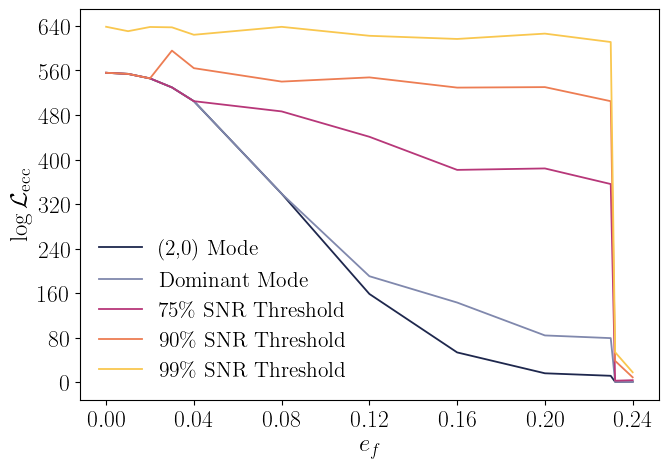

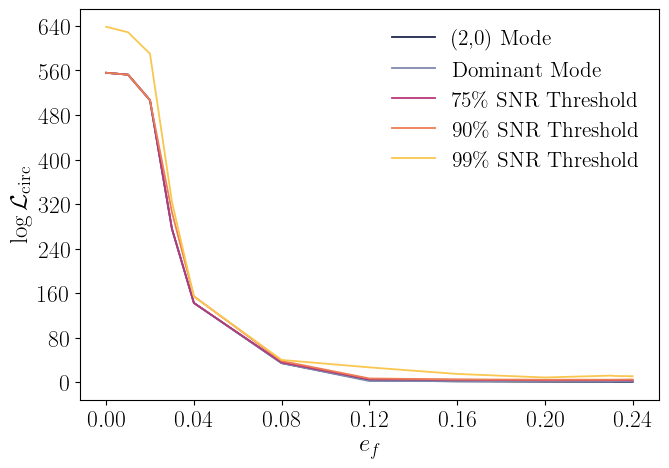

In [5]:
fig_ecc, ax_ecc = plt.subplots(figsize=(7,5))
fig_circ, ax_circ = plt.subplots(figsize=(7,5))

for i, filename in enumerate(filenames):
    
    df = load_hdf5(filename)
    
    vals_ef = df["ef_inj"].values
    vals_logL_ecc = df["logL_ecc"].values
    vals_logL_circ = df["logL_circ"].values
    
    ax_ecc.plot(vals_ef, vals_logL_ecc, '-', lw=1.3, label=labels[i], c=cpal[i])
    ax_circ.plot(vals_ef, vals_logL_circ, '-', lw=1.3, label=labels[i], c=cpal[i])
    
ax_ecc.set_xlabel(r"$e_f$")
ax_ecc.set_ylabel(r"$\log \mathcal L_{\rm ecc}$")
ax_ecc.legend(loc='lower left', fontsize=15.5)
ax_ecc.set_xticks(np.arange(0, 0.241, 0.04))
ax_ecc.set_yticks(np.arange(0, 651, 80))
fig_ecc.tight_layout()

ax_circ.set_xlabel(r"$e_f$")
ax_circ.set_ylabel(r"$\log \mathcal L_{\rm circ}$")
ax_circ.legend(loc='upper right', fontsize=15.5)
ax_circ.set_xticks(np.arange(0, 0.241, 0.04))
ax_circ.set_yticks(np.arange(0, 651, 80))
fig_circ.tight_layout()

#fig_ecc.savefig("../figures/2_logL_eccentric.pdf", bbox_inches='tight')
#fig_circ.savefig("../figures/2_logL_circular.pdf", bbox_inches='tight')

plt.show()

### 2.2. Relative Biases (Eccentric and Circular Hypothesis)

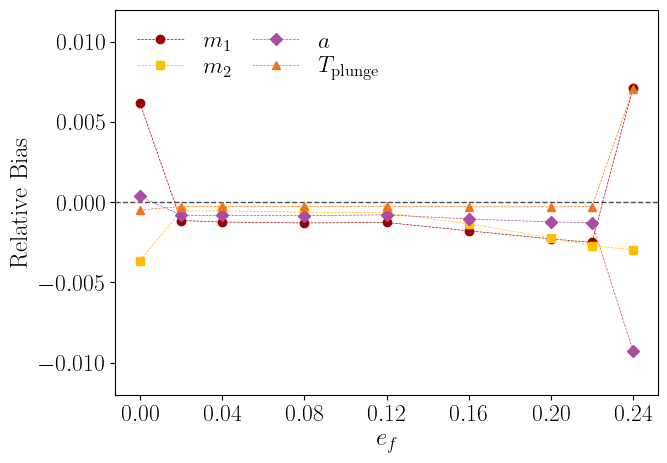

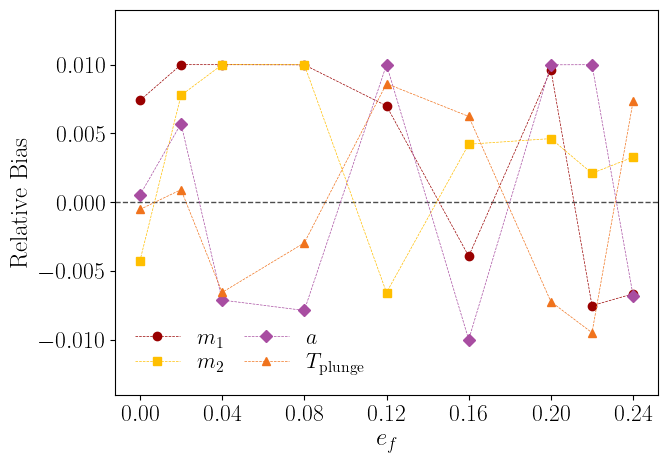

In [6]:
filepath = "../results/2_fid_lambda_ef_99_thr_biases.h5"
df = load_hdf5(filepath)

vals_ef = df["ef_inj"].values
vals_h0_m1 = df["h0_m1"].values
vals_h0_m2 = df["h0_m2"].values
vals_h0_a = df["h0_a"].values
vals_h0_Tpl = df["h0_Tpl"].values
vals_h1_m1 = df["h1_m1"].values
vals_h1_m2 = df["h1_m2"].values
vals_h1_a = df["h1_a"].values
vals_h1_Tpl = df["h1_Tpl"].values
vals_h1_ef = df["h1_ef"].values

cpal_biases = ["#990000",
               "#ffbf00",
               "#a84da1",
               "#f0731d"]

### Plot of the biases relative to the eccentric hypothesis

plt.figure(figsize=(7,5))
plt.axhline(0, color="black", lw=1, ls="--", alpha=0.7)
plt.plot(vals_ef, (10**vals_h1_m1 - m1) / m1, "--", marker="o", color=cpal_biases[0], label=r"$m_1$", lw=0.5)
plt.plot(vals_ef, (vals_h1_m2 - m2) / m2, "--", marker="s", color=cpal_biases[1], label=r"$m_2$", lw=0.5)
plt.plot(vals_ef, (vals_h1_a - a) / a, "--", marker="D", color=cpal_biases[2], label=r"$a$", lw=0.5)
plt.plot(vals_ef, (vals_h1_Tpl - Tpl) / Tpl, "--", marker="^", color=cpal_biases[3], label=r"$T_{\rm plunge}$", lw=0.5)

plt.xticks(np.arange(0, 0.241, 0.04))
plt.yticks(np.arange(-0.010, 0.011, 0.005))
plt.ylim([-0.012, 0.012])
plt.xlabel(r"$e_f$")
plt.ylabel("Relative Bias")
plt.legend(ncols=2, labelspacing=0.2, columnspacing=0.9)
#plt.savefig('../figures/2_bias_eccentric.pdf', bbox_inches='tight')
plt.show()

### Plot of the biases relative to the circular hypothesis

plt.figure(figsize=(7,5))
plt.axhline(0, color="black", lw=1, ls="--", alpha=0.7)
plt.plot(vals_ef, (10**vals_h0_m1 - m1) / m1, "--", marker="o", color=cpal_biases[0], label=r"$m_1$", lw=0.5)
plt.plot(vals_ef, (vals_h0_m2 - m2) / m2, "--", marker="s", color=cpal_biases[1], label=r"$m_2$", lw=0.5)
plt.plot(vals_ef, (vals_h0_a - a) / a, "--", marker="D", color=cpal_biases[2], label=r"$a$", lw=0.5)
plt.plot(vals_ef, (vals_h0_Tpl - Tpl) / Tpl, "--", marker="^", color=cpal_biases[3], label=r"$T_{\rm plunge}$", lw=0.5)
plt.xticks(np.arange(0, 0.241, 0.04))
plt.yticks(np.arange(-0.010, 0.011, 0.005))
plt.ylim([-0.014, 0.014])
plt.xlabel(r"$e_f$")
plt.ylabel("Relative Bias")
plt.legend(ncols=2, fontsize=16, labelspacing=0.2, columnspacing=0.9)
#plt.savefig('../figures/2_bias_circular.pdf', bbox_inches='tight')
plt.show()

### 2.3. Detection Statistic

In [7]:
true_params = np.array([m1, m2, a, Tpl, 0, xI])
vals_ef_beg = np.linspace(0, 0.036, 10)
scaling_beg = np.zeros(len(vals_ef_beg))

for i, ef in enumerate(vals_ef_beg):
    true_params[4] = ef
    t_alpha, true_phi_f_fdot_fddot, amp_alpha = get_frequency_evolution(true_params, T_DATA, T_SFT, DELTA_T)
    f_phi_alpha = true_phi_f_fdot_fddot[1][0]
    K_1 = np.sum(amp_alpha**2 / psd(2 * f_phi_alpha))
    scaling_beg[i] = K_1 * ef**4

Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU


In [8]:
true_params = np.array([m1, m2, a, Tpl, 0, xI])
vals_ef_end = np.linspace(0.22, 0.24, 20)
scaling_end = np.zeros(len(vals_ef_end))

mu = (m1 * m2) / (m1 + m2)
M = m1 + m2
G = sp.constants.G * 1.988e30
c = sp.constants.c

C1 = (np.pi**2 / 224) * T_SFT**6
C2 = (67584 / 25) * (2 * np.pi)**(16/3) * (G**(10/3) * M**(4/3) * mu**2) / (c**10)
C = C1 * C2**2

for i, ef in enumerate(vals_ef_end):
    true_params[4] = ef
    t_alpha, true_phi_f_fdot_fddot, amp_alpha = get_frequency_evolution(true_params, T_DATA, T_SFT, DELTA_T)
    f_phi_alpha = true_phi_f_fdot_fddot[1][0]
    f1 = amp_alpha**2 / psd(2 * f_phi_alpha)
    f2 = C * f_phi_alpha**(38/3) * (1 + 7379/396 * ef**2)
    scaling_end[i] = np.sum(f1 * (1 - f2)**2)

Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Wavefo

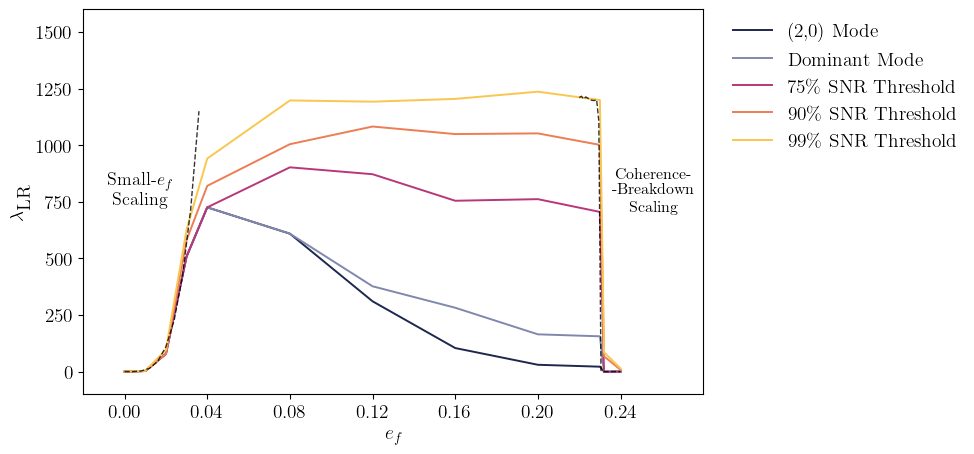

In [9]:
plt.figure(figsize=(8, 5))

for i, filename in enumerate(filenames):
    
    df = load_hdf5(filename)
    
    vals_ef = df["ef_inj"].values
    vals_lambda_LR = df["lambda_LR"].values

    plt.plot(vals_ef, vals_lambda_LR, '-', lw=1.4, label=labels[i], c=cpal[i])

scale = 1150 / scaling_beg[-1]
scaling_beg_plot = scaling_beg * scale

scale = 1210 / scaling_end[0]
scaling_end_plot = scaling_end * scale

plt.plot(vals_ef_beg, scaling_beg_plot, '--', lw=1, c='black', alpha=0.8)
plt.plot(vals_ef_end, scaling_end_plot, '--', lw=1, c='black', alpha=0.8)

plt.text(0.007, 800, "Small-$e_f$ \n Scaling", color='black', fontsize=13, ha='center', va='center')
plt.text(0.256, 800, "Coherence- \n -Breakdown \n Scaling", color='black', fontsize=11.5, ha='center', va='center')

plt.xlabel(r"$e_f$", fontsize=14)
plt.ylabel(r"$\lambda_\textrm{LR}$", fontsize=14)
plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.8), fontsize=14, frameon=False)
plt.xticks(np.arange(0, 0.241, 0.04), fontsize=14)
plt.yticks(fontsize=14)
plt.xlim([-0.02, 0.28])
plt.ylim([-100,1600])
#plt.savefig('../figures/2_det_stats_mode_selection.pdf', bbox_inches='tight')
plt.show()

### 2.4. Comparing with Results Obtained With Larger Priors

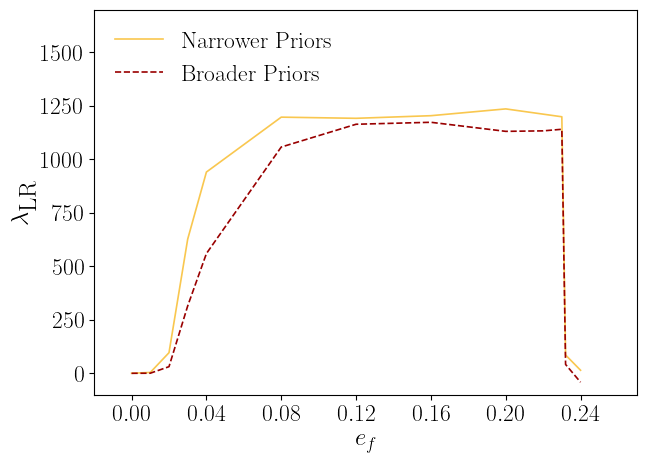

In [10]:
filenames_comp = ["../results/2_fid_lambda_ef_99_thr.h5",
                  "../results/2_fid_lambda_ef_99_thr_larger_bounds.h5",]

labels_comp = [r"Narrower Priors",
               r"Broader Priors"]

cpal_comp = ["#f9c74f", "#990000"]
style_comp = ["-", "--"]

plt.figure(figsize=(7,5))

for i, filename in enumerate(filenames_comp):
    
    df = load_hdf5(filename)
    
    vals_ef = df["ef_inj"].values
    vals_lambda_LR = df["lambda_LR"].values
    
    plt.plot(vals_ef, vals_lambda_LR, style_comp[i], lw=1.2, label=labels_comp[i], c=cpal_comp[i])

plt.xticks(np.arange(0, 0.241, 0.04))
plt.xlim([-0.02, 0.27])
plt.ylim([-100,1700])

plt.xlabel(r"$e_f$")
plt.ylabel(r"$\lambda_\textrm{LR}$")
plt.legend(loc="upper left")
#plt.savefig('../figures/2_det_stats_comp.pdf', bbox_inches='tight')
plt.show()

### 2.5. Impact of Varying the SFT Window

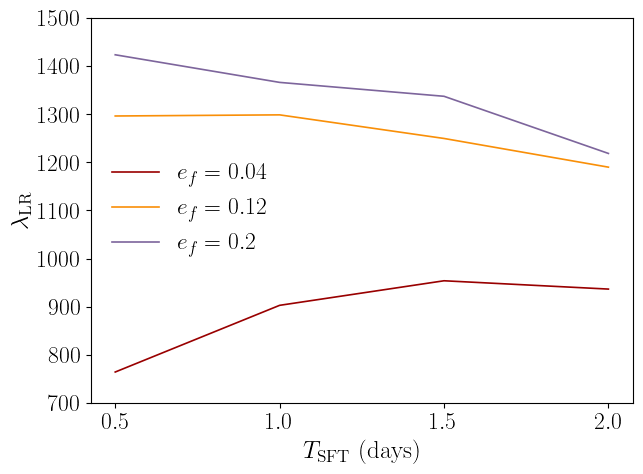

In [11]:
filename = "../results/2_fid_lambda_Tsft_99_thr.h5"

df = load_hdf5(filename)

vals_ef_unique = np.sort(df["ef_inj"].unique())
cpal = color_palette("inferno", len(vals_ef_unique))
cpal = ["#990000",
        "#f98f08",
        "#7D659C"]

plt.figure(figsize=(7,5))

for i, ef in enumerate(vals_ef_unique):

    df_ef = df[df["ef_inj"] == ef].sort_values("t_sft")

    vals_T_SFT = df_ef["t_sft"].values
    vals_lambda_LR = df_ef["lambda_LR"].values

    plt.plot(vals_T_SFT / 86400, vals_lambda_LR, "-", lw=1.2, label=rf"$e_f = {ef}$", c=cpal[i])

plt.xticks(np.arange(0.5, 2.1, 0.5))
plt.yticks(np.arange(700, 1501, 100))
plt.xlabel(r"$T_{\rm SFT}$ (days)")
plt.ylabel(r"$\lambda_{\rm LR}$")
plt.legend(frameon=False,)
#plt.savefig('../figures/2_det_stats_Tsft.pdf', bbox_inches='tight')
plt.show()

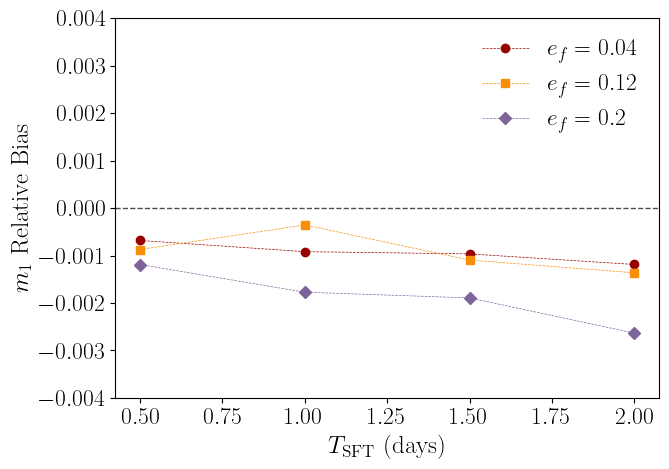

In [12]:
plt.figure(figsize=(7,5))

plt.axhline(0, color="black", lw=1, ls="--", alpha=0.7)

markers = ["o", "s", "D"]

for i, ef in enumerate(vals_ef_unique):

    df_ef = df[df["ef_inj"] == ef].sort_values("t_sft")

    vals_T_SFT = df_ef["t_sft"].values / 86400
    rel_bias_m1 = (10**df_ef["h1_m1"].values - m1) / m1

    plt.plot(vals_T_SFT, rel_bias_m1, "--", marker=markers[i], lw=0.5, label=rf"$e_f = {ef}$", c=cpal[i])

plt.yticks(np.arange(-0.004, 0.0041, 0.001))
plt.ylim([-0.004, 0.004])
plt.xlabel(r"$T_{\rm SFT}$ (days)")
plt.ylabel(r"$m_1$ Relative Bias")
plt.legend(loc="upper right", frameon=False)
plt.tight_layout()
#plt.savefig('../figures/2_biases_Tsft.pdf', bbox_inches='tight')
plt.show()